# Pokémon classifier

Model: [skshmjn/Pokemon-classifier-gen9-1025](https://huggingface.co/skshmjn/Pokemon-classifier-gen9-1025) (ViT, 1025 Pokémon classes)

We compare the predictions on four datasets:
- **pokemon**: images of classes the model was trained on
- **animals**: real animals, which are *not* classes of the model (out-of-distribution)
- **am2k_original**: AM-2k, 2000 real animal photos from 20 categories (out-of-distribution)
- **am2k_bg_removed**: the same AM-2k photos, cut out with the dataset's masks and placed on a white background like the Pokémon images (out-of-distribution)


Pokemon Datasets: 
Pokemon Dataset: https://www.kaggle.com/datasets/hlrhegemony/pokemon-image-dataset

OOD Datasets:
Animal Dataset https://github.com/bruinxiong/animal-matting
AM2K: https://drive.google.com/drive/folders/1SReB9Zma0TDfDhow7P5kiZNMwY9j9xMA 

Predictions are saved to `predictions/` and only computed again if those files are missing.

### Folder structure

`images/`, `models/` and `predictions/` are not in the Git repository (see `.gitignore`). Download the datasets into `images/` yourself; the other two folders are created automatically.

```
ai-and-vis/
├── analysis.ipynb
├── src/
│   ├── pokemon_classifier.py      # model loading, prediction, paths
│   ├── data.py                    # dataset loader: one folder per class
│   └── visualisation.py
├── images/                        # download yourself, one subfolder per class
│   ├── pokemon/<pokemon>/*.jpg    # e.g. pokemon/Pikachu/0.jpg (names must match the model's labels)
│   ├── animals/<animal>/*.jpg     # e.g. animals/bison/79e1610d01.jpg
│   ├── AM-2k-original/<animal>/*.jpg
│   ├── AM-2k-bg-removed/<animal>/*.jpg
│   └── AM-2k_annotations/<animal>/{mask,fg,bg,trimap}/   # not used by the notebook
├── models/                        # created on the first run
└── predictions/                   # created on the first run: <dataset>_predictions.csv, <dataset>_confidences.npy
```

### Model location

`load_model()` downloads the model from Hugging Face on the first run (about 330 MB) and caches it in `models/` (`MODELS_DIR` in `src/pokemon_classifier.py`). Later runs load it from there without downloading it again. To download it again, delete `models/`.

## Setup

In [48]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from pokemon_classifier import (
    PREDICTIONS_DIR,
    device,
    load_model,
    load_datasets,
    load_or_predict,
)
from visualisation import visualise_confidence_vs_entropy

print(f"Device: {device}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Device: cpu


## Load model and datasets

In [49]:
model, image_processor = load_model()
id2label = model.config.id2label
print(f"Number of classes: {model.config.num_labels}")

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 25650.88it/s]

Number of classes: 1025


In [50]:
datasets = load_datasets(model, image_processor)
for dataset in datasets:
    print(f"{dataset.name}: {len(dataset)} images")

pokemon: 2485 images
animals: 5400 images
am2k_original: 2000 images
am2k_bg_removed: 2000 images


## Predictions

The first run predicts every image, which takes a while on CPU. Later runs load the saved files.

- `predictions[name]`: one row per image (path, true and predicted label, confidence, entropy)
- `confidences[name]`: full probability matrix, shape `(num_images, 1025)`. Row `i` belongs to row `i` of the DataFrame.

In [53]:
predictions = {}
confidences = {}
for dataset in datasets:
    predictions[dataset.name], confidences[dataset.name] = load_or_predict(
        dataset, model, image_processor
    )

pokemon_predictions_df = predictions["pokemon"]
animal_predictions_df = predictions["animals"]
am_2k_original_predictions_df = predictions["am2k_original"]
am_2k_bg_removed_predictions_df = predictions["am2k_bg_removed"]
#pokemon_predictions_df.head()

Loading saved predictions for pokemon
Loading saved predictions for animals
Loading saved predictions for am2k_original
Loading saved predictions for am2k_bg_removed


## Overview

In [40]:
pokemon_acc = (pokemon_predictions_df["true_label_id"] == pokemon_predictions_df["predicted_label_id"]).mean()
print(f"Pokémon accuracy: {pokemon_acc:.3f}")

animals_acc = (animal_predictions_df["true_label_id"] == animal_predictions_df["predicted_label_id"]).mean()
print(f"Animals accuracy: {animals_acc:.3f}")

summary = pd.concat(predictions, names=["dataset"])
summary.groupby("dataset")[["confidence", "entropy_norm"]].describe().T

Pokémon accuracy: 0.979
Animals accuracy: 0.000


dataset             am2k_bg_removed  am2k_original      animals      pokemon
confidence   count      2000.000000    2000.000000  5400.000000  2485.000000
             mean          0.182938       0.181022     0.199481     0.951646
             std           0.186638       0.189259     0.203000     0.115746
             min           0.012833       0.012239     0.009978     0.023103
             25%           0.062866       0.062803     0.065021     0.969446
             50%           0.112845       0.107320     0.119859     0.991134
             75%           0.229911       0.218150     0.250716     0.996686
             max           0.994032       0.984407     0.994080     0.999627
entropy_norm count      2000.000000    2000.000000  5400.000000  2485.000000
             mean          0.720020       0.721432     0.701863     0.037819
             std           0.163153       0.166033     0.180234     0.085942
             min           0.009865       0.021795     0.009576     0.000793
             25%           0.667868       0.674001     0.642335     0.005395
             50%           0.770236       0.772634     0.759723     0.012189
             75%           0.830207       0.831042     0.825097     0.031881
             max           0.920064       0.920436     0.928710     0.899202

## Confidence vs. normalized entropy

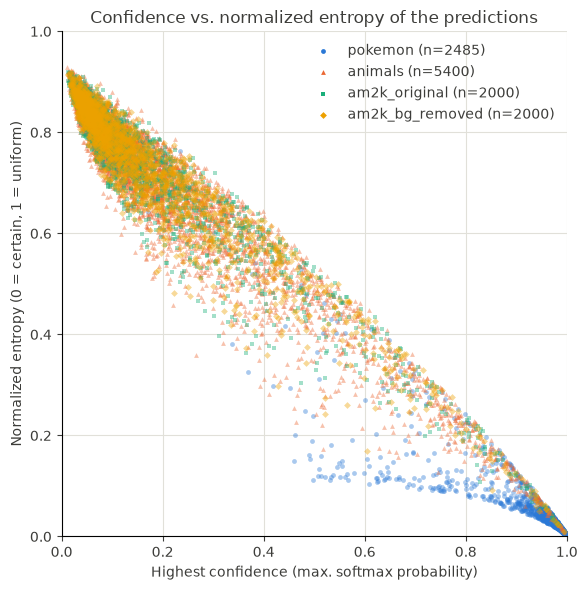

In [54]:
visualise_confidence_vs_entropy(
    predictions, save_path=PREDICTIONS_DIR / "confidence_vs_entropy.png"
)

## Examples

Images with their prediction, e.g. the animals the model is most confident about, or Pokémon it got wrong.

In [55]:
def show_images(df, n=8, cols=4):
    """Show the first n images of a predictions DataFrame with their prediction."""
    df = df.head(n)
    rows = int(np.ceil(len(df) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3.4 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, df.iterrows()):
        ax.imshow(Image.open(row["image_path"]).convert("RGB"))
        ax.set_title(
            f"true: {row['true_label']}\n"
            f"pred: {row['predicted_label']} ({row['confidence']:.2f})",
            fontsize=9,
        )
    fig.tight_layout()
    plt.show()

Dataset: animals


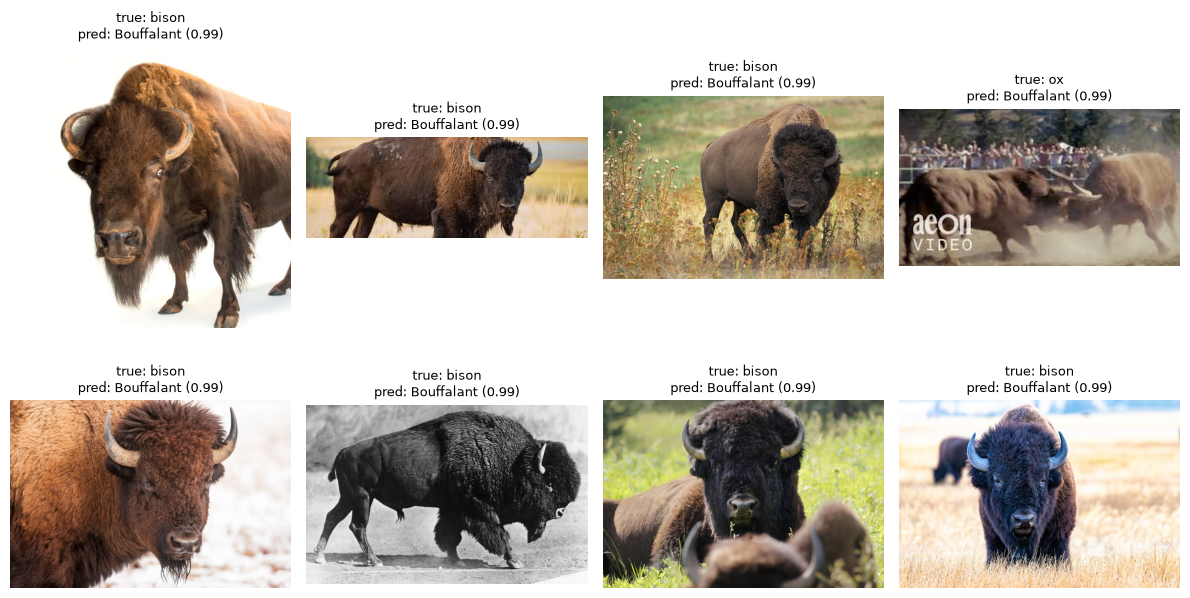

Dataset: am2k_original


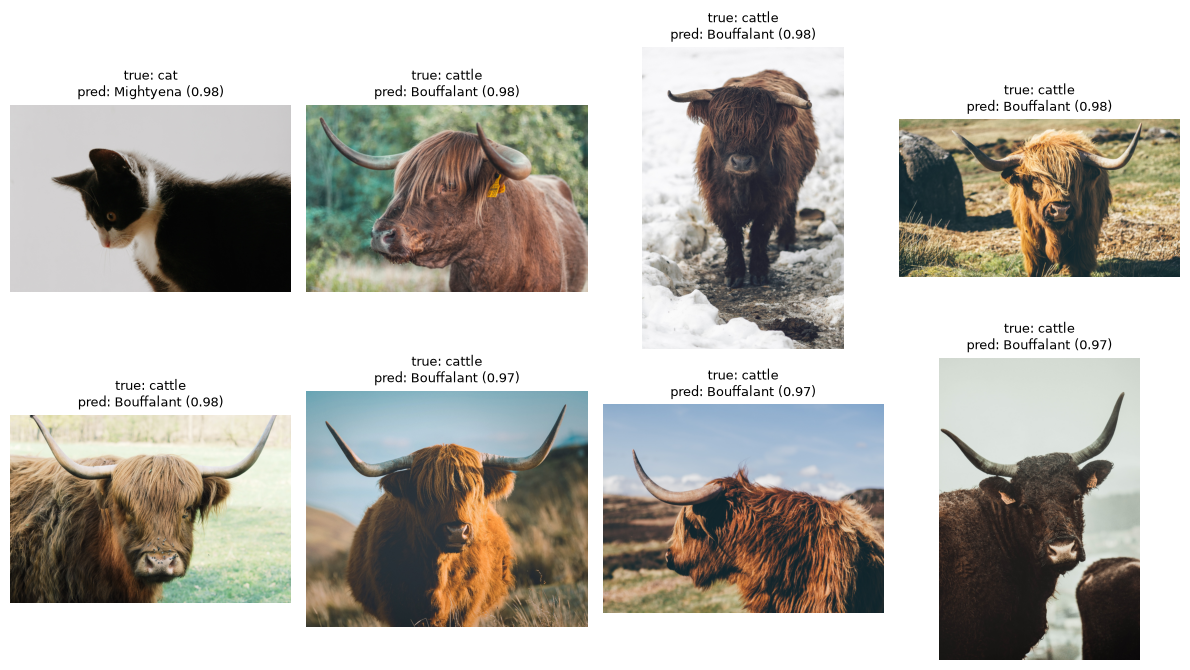

Dataset: am2k_bg_removed


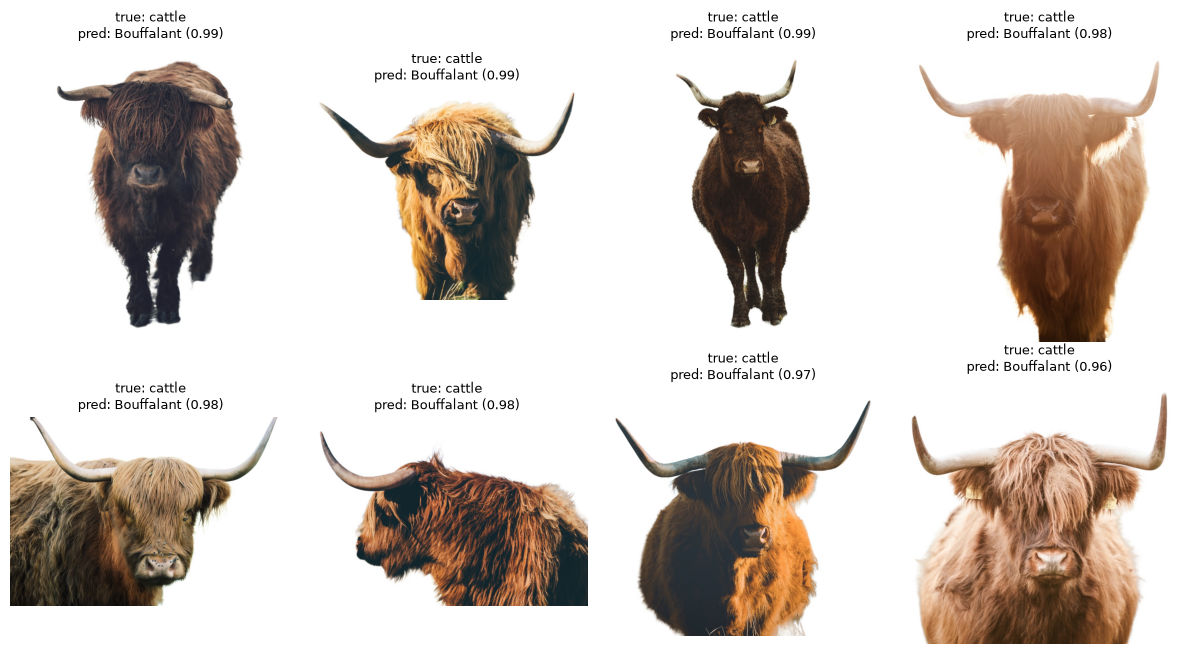

In [56]:
# Animals the model is most confident about (most "Pokémon-like")
for name in ["animals", "am2k_original", "am2k_bg_removed"]:
    print(f"Dataset: {name}")
    show_images(predictions[name].sort_values("confidence", ascending=False))

51 wrong predictions


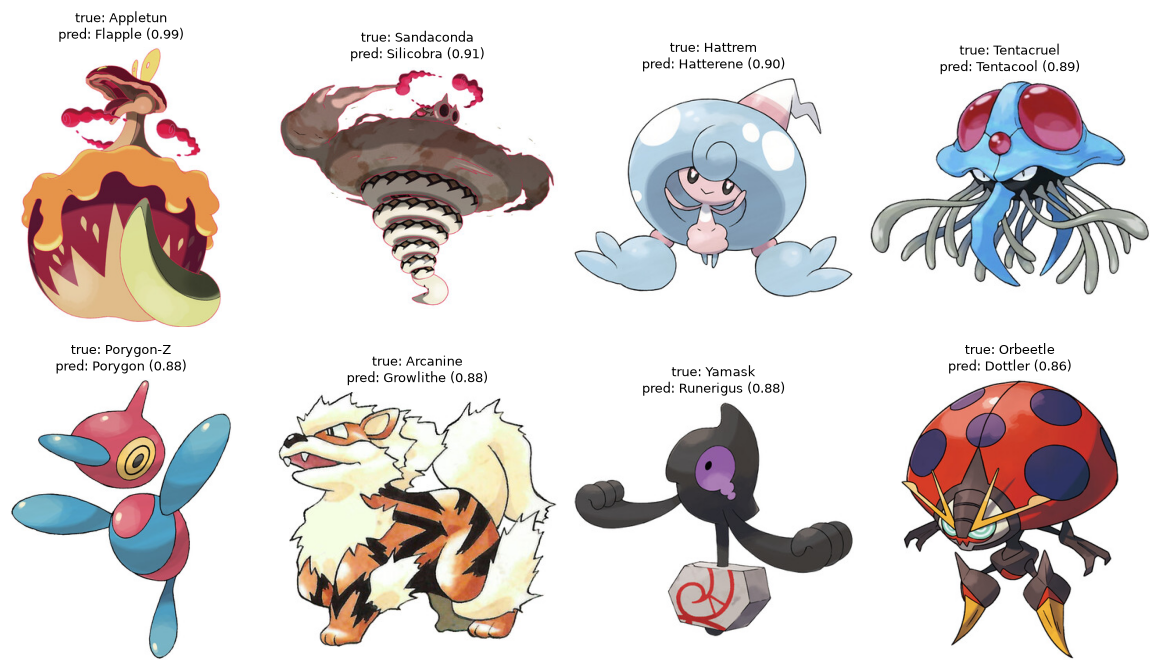

In [57]:
# Wrong Pokémon predictions, most confident first
wrong = pokemon_predictions_df[pokemon_predictions_df["true_label_id"] != pokemon_predictions_df["predicted_label_id"]]
print(f"{len(wrong)} wrong predictions")
show_images(wrong.sort_values("confidence", ascending=False))

## Top-5 predictions of a single image

In [ ]:
def top_k(dataset_name, index, k=5):
    """Top-k classes and probabilities of one image."""
    probs = confidences[dataset_name][index]
    top = np.argsort(probs)[::-1][:k]
    return pd.DataFrame({"label": [id2label[i] for i in top], "probability": probs[top]})


# Most confident image of each animal dataset and its top-5 Pokémon
for name in ["animals", "am2k_original", "am2k_bg_removed"]:
    dataset_predictions = predictions[name]
    index = dataset_predictions["confidence"].idxmax()

    print(f"Dataset: {name}")
    show_images(dataset_predictions.loc[[index]], n=1, cols=1)
    print(top_k(name, index))
    print("\n")

## Confident predictions on animals (confidence > 70 %)

The animal datasets have no correct Pokémon class, so every confident prediction is a confident mistake. Which animals cause them, and which Pokémon do they get mapped to?

In [ ]:
THRESHOLD = 0.7
ANIMAL_DATASETS = ["animals", "am2k_original", "am2k_bg_removed"]

confident = {
    name: predictions[name][predictions[name]["confidence"] > THRESHOLD]
    for name in ANIMAL_DATASETS
}

pd.DataFrame(
    {
        "images": [len(predictions[name]) for name in ANIMAL_DATASETS],
        f"confidence > {THRESHOLD:.0%}": [len(confident[name]) for name in ANIMAL_DATASETS],
        "share": [len(confident[name]) / len(predictions[name]) for name in ANIMAL_DATASETS],
        "mean entropy_norm": [confident[name]["entropy_norm"].mean() for name in ANIMAL_DATASETS],
    },
    index=ANIMAL_DATASETS,
).style.format({"share": "{:.1%}", "mean entropy_norm": "{:.3f}"})

In [ ]:
# Most frequent (animal -> Pokémon) pairs among the confident predictions
for name in ANIMAL_DATASETS:
    pairs = (
        confident[name]
        .groupby(["true_label", "predicted_label"])
        .agg(count=("confidence", "size"), mean_confidence=("confidence", "mean"))
        .sort_values("count", ascending=False)
    )
    print(f"{name}: {len(pairs)} different pairs")
    display(pairs.head(10))

In [ ]:
# One example per (animal -> Pokémon) pair, most frequent pairs first
for name in ANIMAL_DATASETS:
    df = confident[name]
    pair_counts = df.groupby(["true_label", "predicted_label"])["confidence"].transform("size")
    examples = (
        df.assign(pair_count=pair_counts)
        .sort_values(["pair_count", "confidence"], ascending=False)
        .drop_duplicates(["true_label", "predicted_label"])
    )
    print(f"Dataset: {name}")
    show_images(examples, n=8)

### AM-2k: does removing the background change which images are confident?

Both AM-2k datasets contain the same photos, so we can check for each photo whether it is above the threshold in the original, after background removal, or in both.

In [ ]:
def with_file(df):
    return df.assign(file=df["image_path"].map(lambda path: path.split("/")[-1]))


am2k = pd.merge(
    with_file(predictions["am2k_original"]),
    with_file(predictions["am2k_bg_removed"]),
    on=["file", "true_label"],
    suffixes=("_original", "_bg_removed"),
)
above_original = am2k["confidence_original"] > THRESHOLD
above_bg_removed = am2k["confidence_bg_removed"] > THRESHOLD

print(f"Confident in both:              {(above_original & above_bg_removed).sum()}")
print(f"Only in the original:           {(above_original & ~above_bg_removed).sum()}")
print(f"Only after background removal:  {(~above_original & above_bg_removed).sum()}")

# Photos that are confident in only one version: what did the background change?
changed = am2k[above_original != above_bg_removed]
changed[
    ["true_label", "predicted_label_original", "confidence_original",
     "predicted_label_bg_removed", "confidence_bg_removed"]
].sort_values("true_label")